# 07 · Topological data analysis II: point-cloud filtrations

Instead of filtering the pixel grid by intensity, here each image is turned
into a **point cloud**: the pixels above an intensity threshold (regions of
high tau uptake), randomly subsampled to at most 400 points (fixed seed).
Balls of growing radius $r$ are centred on the points; as $r$ grows, nearby
points connect into a **simplicial complex** whose components (H0) and
loops (H1) are tracked.

| filtration | complex | notes |
|---|---|---|
| Vietoris–Rips | edge when two points are within $r$ | classic, expensive |
| Delaunay–Čech | Čech complex restricted to the Delaunay triangulation | same persistence as Čech, fast |
| alpha | alpha complex | fast, geometrically faithful |
| weighted Rips | Rips where each point's weight depends on its intensity (strong signal enters first) | slowest |

Radii are in pixels and capped per filtration (22–54 px). Features still
alive at the cap are kept with death = cap. The data split, vectorisations
and classifiers are the same as in notebook 06.

In [1]:
import time

import matplotlib.pyplot as plt
import pandas as pd

from adni_tau.paths import save_figure, save_table
from adni_tau.tda import config
from adni_tau.tda.classification import (
    cross_validate_logistic_multiview,
    fit_eval_logistic_multiview,
    run_nearest_template_classification,
    summarize_results,
)
from adni_tau.tda.data import load_all_views
from adni_tau.tda.plotting import plot_curve_bands_by_view, plot_point_cloud_threshold_preview
from adni_tau.tda.templates import compute_class_templates_for_view, compute_template_tda
from adni_tau.tda.topology import compute_tda_for_images

plt.rcParams["figure.dpi"] = 90
VIEWS = ["axial", "coronal", "sagittal"]
FILTRATIONS = ["alpha", "delaunaycech", "rips", "weighted_rips"]
THRESHOLD_BY_VIEW = {"axial": 0.3, "coronal": 0.3, "sagittal": 0.3}
LOGIT_C = 0.1

data_by_view = load_all_views(VIEWS)
y_train, y_test = data_by_view[VIEWS[0]]["y_train"], data_by_view[VIEWS[0]]["y_test"]

templates_by_view = {
    v: compute_class_templates_for_view(data_by_view[v]["train_imgs"], y_train, lower_star_threshold=THRESHOLD_BY_VIEW[v], point_cloud_threshold=THRESHOLD_BY_VIEW[v])
    for v in VIEWS
}

   axial: train (192, 182, 218), test (20, 182, 218)


 coronal: train (192, 182, 182), test (20, 182, 182)


sagittal: train (192, 182, 218), test (20, 182, 218)


## 1. Choosing the threshold: the complex at growing radii

The class-template point cloud (pixels above the threshold in at least half
of the training subjects of that class) with its alpha complex at
increasing radii. At small radii there are only isolated points; at large
radii triangles fill the foreground and the topology disappears. A good
threshold keeps the high-uptake regions without filling the whole brain.

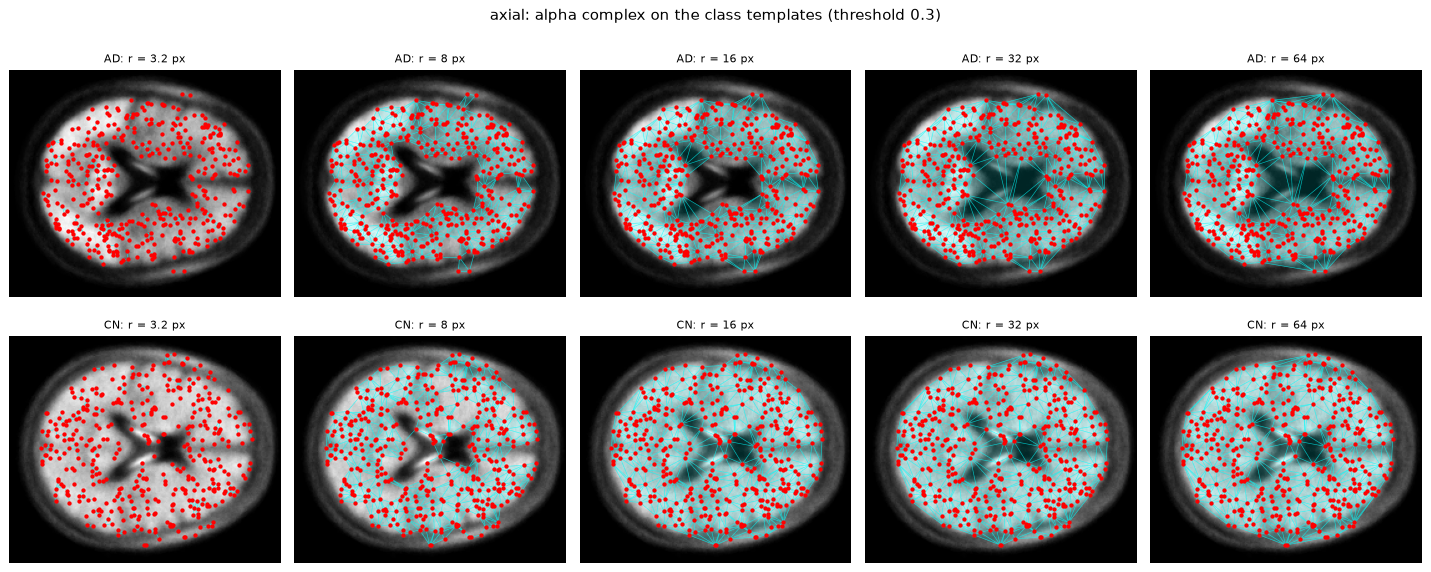

In [2]:
fig = plot_point_cloud_threshold_preview(templates_by_view["axial"], "axial", filtration_type="alpha")
save_figure(fig, "07_alpha_complex_growth_axial")

## 2. TDA, nearest template and logistic regression for every filtration

In [3]:
all_results, cv_rows, tda_by_filtration = [], [], {}
for ftype in FILTRATIONS:
    t0 = time.time()
    tda = {
        v: {part: compute_tda_for_images(data_by_view[v][f"{part}_imgs"], filtration_type=ftype, threshold=THRESHOLD_BY_VIEW[v]) for part in ("train", "test")}
        for v in VIEWS
    }
    tda_by_filtration[ftype] = tda
    templates_tda = {v: compute_template_tda(templates_by_view[v], filtration_type=ftype) for v in VIEWS}

    res = []
    for metric in ("bottleneck", "wasserstein"):
        res.append(run_nearest_template_classification(tda, templates_tda, y_test, VIEWS, metric=metric, verbose=False)[1])
    logit = fit_eval_logistic_multiview(tda, y_train, y_test, VIEWS, C=LOGIT_C, verbose=False, name="Logistic regression")
    res += [logit["metrics_train"], logit["metrics_test"]]
    for m in res:
        all_results.append({**m, "name": f"{ftype}: {m['name']}"})

    cv = cross_validate_logistic_multiview(tda, y_train, y_test, VIEWS, C=LOGIT_C)
    cv_rows.append({"filtration": ftype, **cv})
    print(f"{ftype:>14}: done in {time.time() - t0:5.1f}s | logistic test acc {logit['metrics_test']['accuracy']:.2f} | CV acc {cv['cv_accuracy_mean']:.3f} ± {cv['cv_accuracy_std']:.3f}")

         alpha: done in  55.8s | logistic test acc 0.70 | CV acc 0.672 ± 0.055


  delaunaycech: done in  59.4s | logistic test acc 0.70 | CV acc 0.688 ± 0.058


          rips: done in 316.9s | logistic test acc 0.65 | CV acc 0.740 ± 0.054


 weighted_rips: done in 1167.5s | logistic test acc 0.80 | CV acc 0.774 ± 0.057


## 3. Comparison

In [4]:
summary = summarize_results(all_results)
save_table(summary, "07_point_cloud_results")
summary.round(3)

,model,split,accuracy,balanced_accuracy
0,alpha: Nearest template (bottleneck),test,0.65,0.65
1,alpha: Nearest template (wasserstein),test,0.65,0.65
2,alpha: Logistic regression,train,1.00,1.00
3,alpha: Logistic regression,test,0.70,0.70
4,delaunaycech: Nearest template (bottleneck),test,0.60,0.60
5,delaunaycech: Nearest template (wasserstein),test,0.65,0.65
6,delaunaycech: Logistic regression,train,1.00,1.00
7,delaunaycech: Logistic regression,test,0.70,0.70
8,rips: Nearest template (bottleneck),test,0.65,0.65
9,rips: Nearest template (wasserstein),test,0.60,0.60


In [5]:
cv_table = pd.DataFrame(cv_rows).set_index("filtration")
save_table(cv_table.reset_index(), "07_point_cloud_cv")
cv_table.round(3)

,cv_accuracy_mean,cv_accuracy_std,cv_balanced_accuracy_mean,cv_balanced_accuracy_std
filtration,,,,
alpha,0.672,0.055,0.672,0.055
delaunaycech,0.688,0.058,0.688,0.058
rips,0.740,0.054,0.740,0.054
weighted_rips,0.774,0.057,0.774,0.057


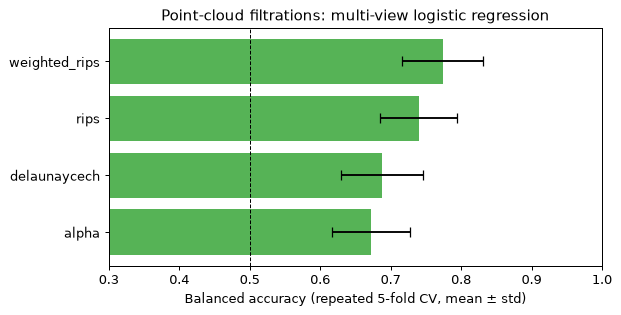

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(cv_table.index, cv_table["cv_balanced_accuracy_mean"], xerr=cv_table["cv_balanced_accuracy_std"], color="tab:green", alpha=0.8, capsize=4)
ax.axvline(0.5, color="k", linestyle="--", linewidth=0.8)
ax.set(xlim=(0.3, 1), xlabel="Balanced accuracy (repeated 5-fold CV, mean ± std)", title="Point-cloud filtrations: multi-view logistic regression")
fig.tight_layout()
save_figure(fig, "07_point_cloud_cv")

**Reading the comparison.**

- **Weighted Rips is the best filtration** (CV balanced accuracy ≈ 0.77),
  followed by plain Rips (≈ 0.74). Weighting each point by its intensity
  adds information that pure geometry misses: *where* the high-uptake
  pixels are and *how strong* the uptake is.
- **Alpha and Delaunay–Čech** (≈ 0.67–0.69) are much faster but less
  discriminative here. At the configured radii their complexes fill in
  quickly and retain fewer H0/H1 features (minimum persistence 4 px).
- **All point-cloud filtrations beat the lower-star filtration**
  (CV ≈ 0.67, notebook 06), and nearest-template now sits above chance
  (0.60–0.65 on the 20 test subjects).
- Train accuracy is 1.0 everywhere: the logistic model separates the
  training set perfectly, so held-out and cross-validated estimates are the
  only meaningful ones.

### Betti curves of the alpha filtration

For point clouds the filtration parameter is a radius in pixels: H0 counts
clusters of high-uptake pixels that have not merged yet, and H1 counts
holes enclosed by them.

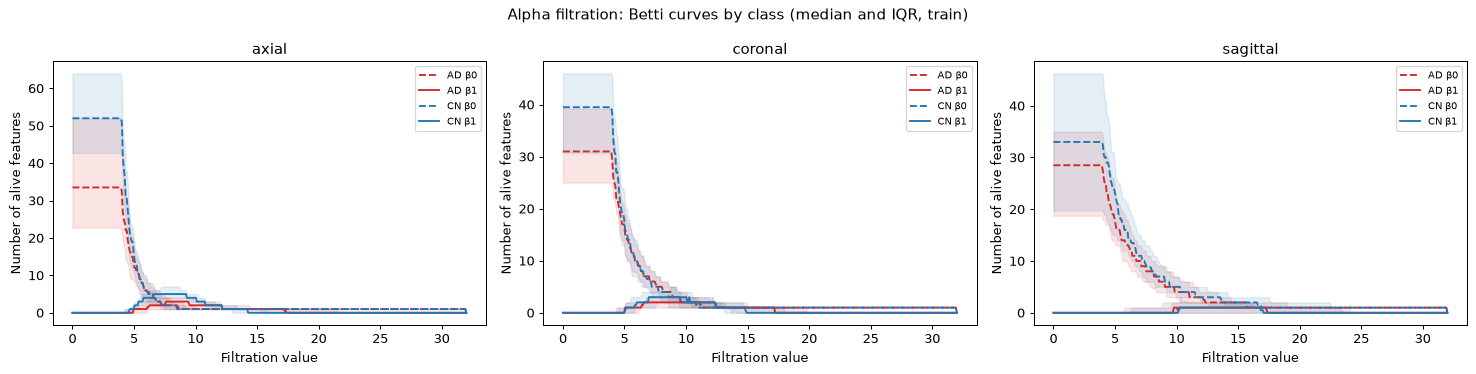

In [7]:
fig = plot_curve_bands_by_view(tda_by_filtration["alpha"], y_train, VIEWS, kind="betti", sample_range=config.LANDSCAPE_RANGE_BY_FILTRATION["alpha"], title="Alpha filtration: Betti curves by class (median and IQR, train)")
save_figure(fig, "07_alpha_betti_curves")